![logo](https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/Helmholtz-AI.png?raw=true)

# Model-Agnostic Interpretation with Permutation Feature Importance

In this notebook, we will demonstrate how to use the Permutation Feature Importance method and interpret its results.

--------

## Getting Started

### Setup Colab environment

If you installed the packages and requirements on your machine, you can skip this section and start from the import section.
Otherwise, you can follow and execute the tutorial on your browser. To start working on the notebook, click on the following button. This will open this page in the Colab environment, and you will be able to execute the code on your own.

<a href="https://colab.research.google.com/github/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/xai-for-random-forest/Gen-1-Tutorial_PermutationFeatureImportance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now that you opened the notebook in Colab, run the next cell. It fetches the tutorials and installs the requirements. Running the notebook locally, that cell does nothing: you already have the repository and the requirements.

**Note:** Google Colab may ask you to restart the runtime after installing the required packages. If prompted, restart the runtime before continuing with the notebook.

In [1]:
# On Google Colab: fetch the course and install the requirements.
# Running locally this cell does nothing, because you already have the repository and installed the requirements yourself.
try:
    import google.colab  
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %cd /content
    !rm -rf XAI-Tutorials
    !git clone --depth 1 --branch main https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials.git
    %cd XAI-Tutorials
    !pip install -r requirements_xai-for-random-forest.txt
    %cd xai-for-random-forest


### Imports

Let's start with importing all required Python packages.

In [2]:
import sys
import pickle

import numpy as np

from sklearn.metrics import get_scorer
from sklearn.inspection import permutation_importance

# Make the local plotting helpers available.
sys.path.append("./")
import utils

# Fix the seed so that random operations can be reproduced.
seed = 1
np.random.seed(seed)

--------

## Introduction to Permutation Feature Importance

**We prepared a small [Introduction to Permutation Feature Importance](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/pfi.html) for you, to help you understand how this method works.**

*Note: we provide all references [here](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/pfi.html#references).*


<font color='green'>

#### Questionnaire:

1. What is achieved by permuting a feature’s values?

   A) The feature is removed from the dataset so that the model cannot use it.  
   B) The feature’s values are shuffled across samples, disrupting their associations with the target and other features while preserving the feature’s overall distribution.  
   C) The feature’s values are replaced with random numbers drawn from a different distribution.  
   D) The feature and target are shuffled together, preserving their relationship.  

2. Why do we shuffle individual features rather than the target when calculating PFI?

   A) Shuffling the target would require retraining the model.  
   B) Shuffling the target would change the number of samples in the dataset.  
   C) Shuffling the target would always improve the model’s performance.  
   D) Shuffling the target would disrupt its relationship with all features at once, rather than isolate the model’s reliance on one feature.  

3. Why do we shuffle a feature rather than remove it when calculating PFI?

   A) Shuffling preserves the input structure, allowing us to evaluate the same trained model. Removing a feature would generally require training a different model.  
   B) Shuffling ensures that every feature receives a positive importance value.  
   C) Removing a feature would also remove its corresponding target values.  
   D) Shuffling allows the model to learn how to compensate for the disrupted feature.  

4. What does a negative permutation importance value mean?

   A) The feature decreases the predicted target value.  
   B) The model cannot make predictions without the feature.  
   C) The model performs better after the feature’s values are shuffled.  
   D) The feature should always be removed immediately.  

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

1. What is achieved by permuting a feature’s values?

   ⚪ A) Permutation does not remove the feature. The column remains in the dataset, but its values are reassigned to different samples.  
   🟢 B) Permutation shuffles the existing values across samples. This disrupts their original associations with the target and other features while preserving the values and their frequencies. Some associations may remain by chance in an individual shuffle.  
   ⚪ C) Permutation uses the feature’s existing values rather than generating new random values.  
   ⚪ D) Only the selected feature is shuffled. The target and all other features remain unchanged.  

2. Why do we shuffle individual features rather than the target when calculating PFI?

   ⚪ A) Shuffling the target does not itself require retraining. The problem is that the resulting performance change would not isolate the importance of one feature.  
   ⚪ B) Shuffling changes the assignment of values to samples, not the number of samples.  
   ⚪ C) Shuffling the target does not systematically improve performance. It disrupts the alignment between the inputs and their correct target values.  
   🟢 D) Shuffling the target disrupts its alignment with all features simultaneously. The resulting performance change therefore cannot be attributed to one feature.  

3. Why do we shuffle a feature rather than remove it when calculating PFI?

   🟢 A) Shuffling keeps the input structure unchanged, so we can evaluate the original model without retraining. Removing a feature and retraining would instead measure how well a different model performs without that feature.  
   ⚪ B) PFI values can be positive, close to zero, or negative, depending on how performance changes after shuffling.  
   ⚪ C) Removing a feature removes an input column, not the corresponding target values.  
   ⚪ D) The model is not retrained during PFI, so it does not learn to compensate for the shuffled feature.  

4. What does a negative permutation importance value mean?

   ⚪ A) PFI measures changes in predictive performance, not whether a feature increases or decreases the predicted target value.  
   ⚪ B) Negative importance does not mean that predictions are impossible without the feature. It describes an improvement in performance after shuffling.  
   🟢 C) Negative importance means that the model performs better after the feature is shuffled. This may reflect random variation or patterns learned by the model that do not generalize well. If the result is consistent across repetitions, it may be worth evaluating a retrained model without the feature.  
   ⚪ D) A negative estimate alone is not sufficient reason to remove a feature. First check whether the result is stable, and validate whether removing the feature and retraining actually improves performance.  

</div>

--------

## Data and Model Loading: The California Housing Dataset

In this notebook, we will work with the **California Housing dataset**, containing 20,640 median house values for California districts (expressed in $100,000), which are described by 8 numeric features. Each row in the dataset represents a block of houses, not a single household. The data pertains to the house prices found in a given California district and some summary statistics about them based on the 1990 census data. Our goal is to **predict the price** of house blocks and find the most predictive features.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/dataset_california_housing.jpg?raw=true" width="900" /></center>

<font size=1> Source: [Link](https://www.kaggle.com/datasets/harrywang/housing)

In the notebook [*Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb*](./Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb), we explain how to do the exploratory data analysis, preprocess the data and train a Random Forest model with the given data. The focus of this notebook is the interpretation of the previously trained model.

In [3]:
# Load the saved data splits and the already trained model.
# Only load pickle files from trusted sources.
with open("../models/model_rf_housing.pickle", "rb") as handle:
    X_train, X_test, y_train, y_test, model_housing, _ = pickle.load(handle)

# For this regressor, .score() returns R²; it does not train the model.
print(f"Model Performance on training data: {model_housing.score(X_train, y_train):.2f} R^2.")
print(f"Model Performance on test data: {model_housing.score(X_test, y_test):.2f} R^2.")

Model Performance on training data: 0.84 R^2.
Model Performance on test data: 0.72 R^2.


As we can see by the numbers above, our model performs well on the training set and also generalizes well to the independent test set.

**You should keep in mind that interpreting a low-performing model can lead to wrong conclusions.**

*Note: The $R^2$ is the coefficient of determination, and the closer this value is to 1, the better our model explains the data. A constant model that always predicts the average target value disregarding the input features would get an $R^2$ score of 0. However, the $R^2$ score can also be negative because the model can be arbitrarily worse.*

## Now, what does my model actually think is important in the data?

Now, let's use Permutation Feature Importance to get insights into the Random Forest Regression model we loaded above. We can use the scikit-learn implementation called `permutation_importance` to get the importance values for the features in our model. For measuring the performance drop when permuting a feature, we use the standard metric of our trained model, which is, in our case, the $R^2$ score. Using the same score enables us to evaluate the performance drop in relation to the baseline performance. We do 20 repetitions of permutation for each feature to get more reliable results.

*Note: this method is a **global** method, which means that it only provides explanations for the full dataset but not for individual examples.*

*Note: Features that are deemed of low importance for a bad model (low test score) could be very important for a good model. Therefore, it is always important to evaluate the predictive power of a model using a held-out set prior to computing importances. Permutation importance does not reflect the intrinsic predictive value of a feature by itself but how important this feature is for a particular model.*

In [4]:
# Convert the metric name into a scorer that permutation_importance can use.
scorer = get_scorer("r2")

In [5]:
# Evaluate the existing model without retraining it.
explanation_train = permutation_importance(
    model_housing,
    X=X_train,
    y=y_train,
    n_repeats=20,        # Shuffle each feature 20 times to assess variability.
    random_state=seed,  # Make the random permutations reproducible.
    scoring=scorer
)

# Each importance is the original score minus the score after shuffling.
# The result contains all repetitions, their means, and their standard deviations.

# Attach feature names in the same order as the importance values.
explanation_train["feature"] = X_train.columns

We will now plot bar plots for visualizing the importance of each feature as obtained by the mean over the 20 repetitions. 

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


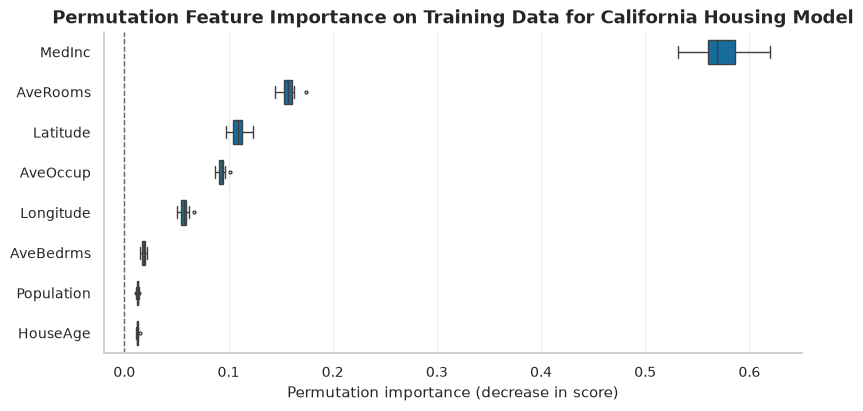

In [6]:
utils.plot_permutation_feature_importance(explanation_train, X_train, 'Permutation Feature Importance on Training Data for California Housing Model')

Features with the largest importance score are the ones whose score is most decreased when the feature is permuted, indicating high relevance for the prediction of the target. For our California Housing model, the *median income in a block group* seems to have the highest impact on the model performance. Permuting this feature leads to an $R^2$ score decrease of ~0.6. When comparing it to the baseline $R^2$ score of 0.84, we notice that permuting the *median income* feature leads to a much lower $R^2$ of about 0.24, so the model loses most of its predictive power without this feature.

We are not restricted to obtaining feature importances for the same dataset we used to train the model. Instead, we could use the same approach to identify the most important features in the test set.

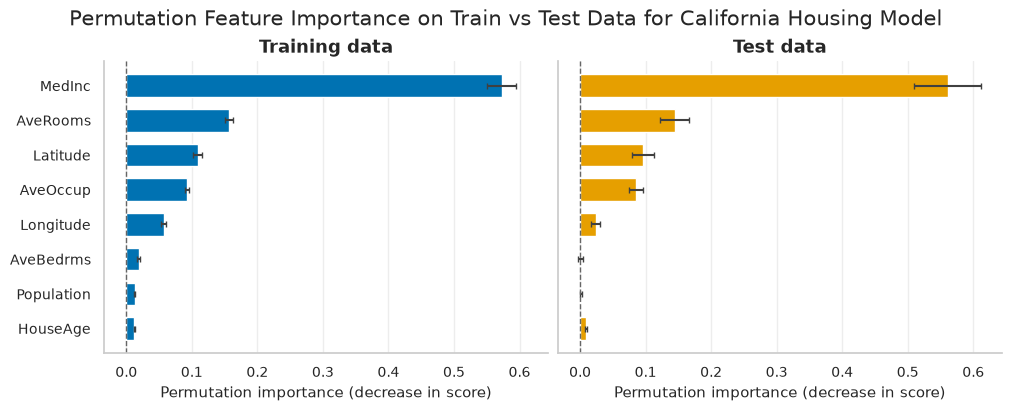

In [7]:
# Keep the model fixed, but evaluate feature reliance on unseen samples.
# Use the same metric and number of repetitions as for the training data.
explanation_test = permutation_importance(
    model_housing,
    X=X_test,
    y=y_test,
    n_repeats=20,
    random_state=seed,
    scoring=scorer
)

explanation_test["feature"] = X_test.columns

utils.plot_permutation_feature_importance_train_vs_test(explanation_train, X_train, explanation_test, X_test, 'Permutation Feature Importance on Train vs Test Data for California Housing Model')

It seems that for both datasets, largely the same features are identified as important, which is reassuring.

*Note: this agreement of important features between training and testing datasets is not guaranteed. In such cases, it is not straightforward to decide on the "truly important" features for the model.*

<font color='green'>

#### Question: Does low importance mean we can remove a feature?

Suppose we add a second measurement of median income to the California Housing dataset. The two income features are almost identical, and we train a new Random Forest using both. The model performs well on unseen test data. However, shuffling either income feature individually causes only a small decrease in performance. A colleague concludes: “Neither income feature is important, so we can safely remove both.”

Do you agree? Explain how both features could receive low permutation importance despite containing useful information. What would you expect if you shuffled both features together, using the same row permutation? How would you test whether both features can actually be removed?

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

Not necessarily. The two income features contain overlapping information. If the trained model uses both as substitutes, shuffling one may have little effect because the other still provides useful information. Low individual PFI therefore does not establish that both features are unnecessary. Shuffling both features together, using the same row permutation, preserves their relationship with each other but disrupts their alignment with the target and the remaining features. If the model relies strongly on their shared information, we would expect a larger performance decrease than when shuffling either feature alone. This joint permutation measures the **existing model’s reliance on the pair**. To test whether both features can be removed, we would instead retrain a model without them and compare its performance using the same validation procedure. The retrained model might learn to use other features, so its performance cannot be inferred directly from PFI.

</div>

--------

<font color='green'>

### Task: Apply Permutation Feature Importance to the Wine Dataset

In this exercise, you will apply **Permutation Feature Importance (PFI)** to trained Random Forest classifiers to investigate which chemical properties the models rely on to classify wines.

Your task is to:

1. Define an appropriate evaluation metric (`scoring`) for multiclass classification using `get_scorer`.
2. Compute permutation importance for `model_wine` using its training data, 20 repetitions, the chosen scorer, and `random_state=seed`.
3. Compute permutation importance for `model_wine_sel` using its reduced training data and the same settings.

Compare the resulting importance plots. Which features receive the highest importance in each model? Explain why removing correlated features can change the importance of the remaining features.

> **Hint:** The evaluation metric determines which aspect of predictive performance PFI measures. For multiclass classification, `"accuracy"` and `"f1_macro"` are common choices.

> **Hint:** Correlated features can provide overlapping information. Shuffling one may have little effect if the trained model can still use another feature containing similar information.

</font>

**The Wine dataset**

Let's use the wine quality dataset to see how XAI can be used to explain multiclass classification models. The **Wine Recognition dataset** contains 178 wine samples from three different cultivars of wine in the same region in Italy. The wine was chemically analyzed and 13 different chemical attributes like *alcohol*, *malic acid*, *flavanoids*, etc. were measured. Our goal is to **classify wines** and find the most predictive features.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/dataset_red_wine.jpg?raw=true" width="900" /></center>

<font size=1> Source:
[Link](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)

In the notebook [*Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb*](./Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb), we explain how to do the exploratory data analysis, preprocess the data and train a Random Forest model with the given data. The focus of this notebook lies on the interpretation of the previously trained model.

In [8]:
# Replace the housing data with the wine data and its trained classifier.
with open("../models/model_rf_wine.pickle", "rb") as handle:
    X_train, X_test, y_train, y_test, model_wine, _ = pickle.load(handle)

# For this classifier, .score() returns accuracy rather than R².
print(f"Model Performance on training data: {model_wine.score(X_train, y_train) * 100:.2f}% accuracy.")
print(f"Model Performance on test data: {model_wine.score(X_test, y_test) * 100:.2f}% accuracy.")

Model Performance on training data: 100.00% accuracy.
Model Performance on test data: 97.22% accuracy.


As shown by the metrics above, the model achieves perfect performance on the training set while also generalizing very well to the independent test set.

**Understanding Feature Importance in the Wine Dataset**

We can now apply Permutation Feature Importance to better understand how the trained model uses the different chemical properties to distinguish between the three wine classes.

In [ ]:
# TASK: Choose a suitable evaluation metric and create the corresponding scorer.
# <add your code here>
scorer = get_scorer("accuracy")

In [ ]:
# TASK: Compute permutation importance for the model trained on all features.
# <add your code here>
explanation_train = permutation_importance(
    model_wine,
    X=X_train,
    y=y_train,
    n_repeats=20,
    random_state=seed,
    scoring=scorer
)
explanation_train["feature"] = X_train.columns  

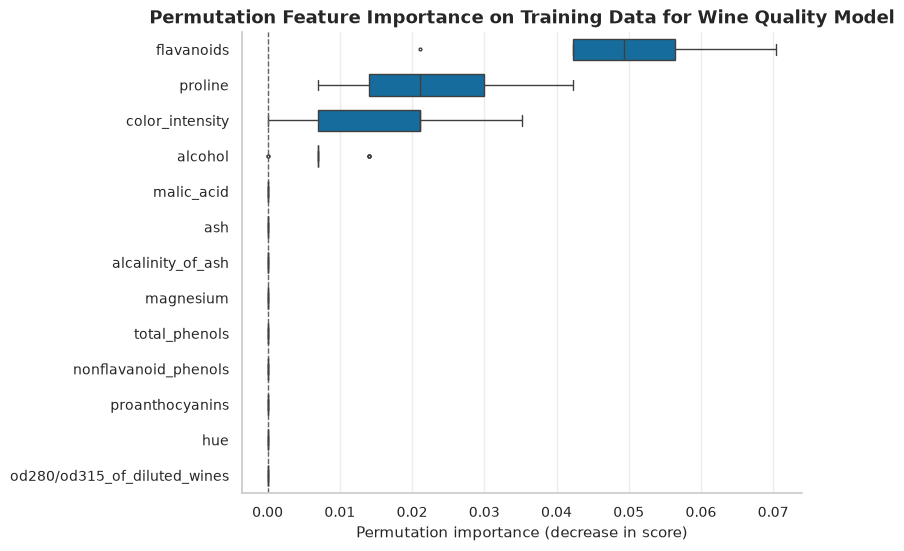

In [11]:
utils.plot_permutation_feature_importance(explanation_train, X_train, 'Permutation Feature Importance on Training Data for Wine Quality Model')

**The Impact of Feature Correlation on Feature Importance**

The correlation matrix helps explain why many features received very low permutation importance scores in the previous analysis. Several chemical properties in the wine dataset show strong positive or negative correlations, meaning that they contain overlapping information about the wine classes. For example, features such as flavanoids, total phenols, and od280/od315_of_diluted_wines are strongly positively correlated, while nonflavanoid phenols exhibits strong negative correlations with several of these variables. Similarly, color intensity and hue show a pronounced negative correlation.

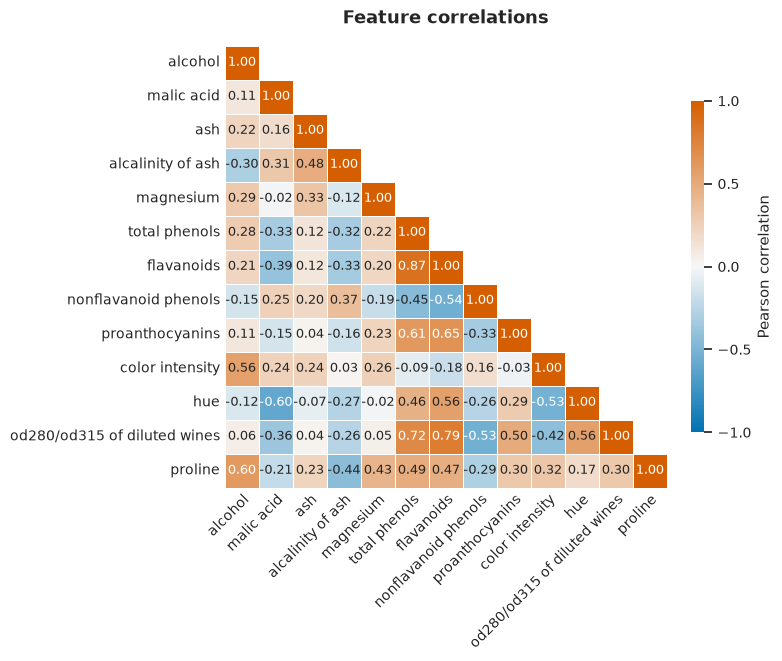

In [12]:
# Look for features that may contain overlapping information.
# Correlation describes relationships between inputs, not model reliance.
utils.plot_correlation_matrix(X_train)

Because of these dependencies, permuting one feature often does not strongly reduce model performance: the Random Forest can still rely on correlated features that contain similar information. As a result, only a few representative variables may appear highly important in the permutation importance ranking, while other correlated but still informative features receive artificially low importance scores. To better understand this effect, we will now compare the results with a model trained on a reduced set of less correlated features obtained through hierarchical clustering-based feature selection. This allows us to investigate how removing redundant variables influences the stability and interpretability of permutation feature importance scores.

In [13]:
with open('../models/model_rf_wine_sel.pickle', 'rb') as handle:
    X_train_sel, X_test_sel, y_train_sel, y_test_sel, model_wine_sel  = pickle.load(handle)

print(f'Model Performance on training data: {round(model_wine_sel.score(X_train_sel, y_train_sel)*100,2)} % accuracy.')
print(f'Model Performance on test data: {round(model_wine_sel.score(X_test_sel, y_test_sel)*100,2)} % accuracy.')

Model Performance on training data: 99.3 % accuracy.
Model Performance on test data: 83.33 % accuracy.


In [ ]:
# TASK: Compute permutation importance for the reduced model using comparable settings.
# <add your code here>
explanation_train_sel = permutation_importance(
    model_wine_sel,
    X=X_train_sel,
    y=y_train_sel,
    n_repeats=20,
    random_state=seed,
    scoring=scorer
)
explanation_train_sel["feature"] = X_train.columns

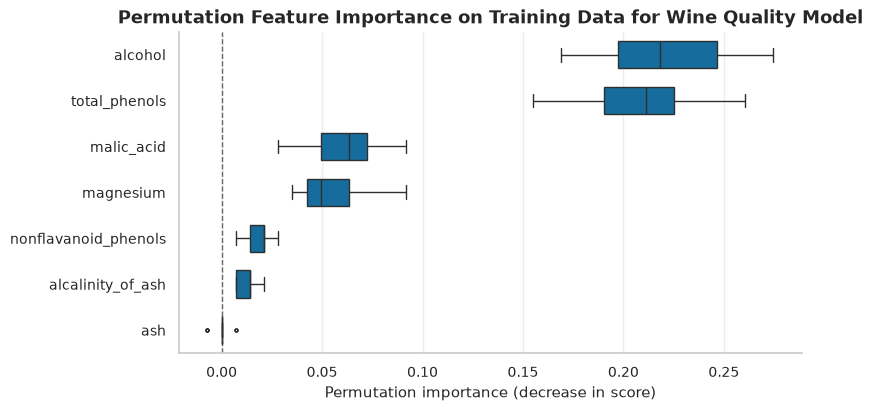

In [15]:
utils.plot_permutation_feature_importance(explanation_train_sel, X_train_sel, 'Permutation Feature Importance on Training Data for Wine Quality Model')

<font color='green'>

#### Conclusions

After removing strongly correlated features, the permutation feature importance results become substantially more interpretable and stable. In contrast to the previous model trained on the full feature set, the importance is now distributed across multiple remaining features rather than being dominated by only a few correlated variables.

Features such as **alcohol** and **total phenols** now emerge as the most influential predictors, while additional variables like **magnesium** and **malic acid** also receive meaningful importance scores. This indicates that the model can no longer rely on redundant correlated features and therefore has to use the remaining variables more directly for its predictions.

Overall, this comparison demonstrates how strongly correlated features can distort permutation importance estimates. Removing redundant variables through correlation-based feature selection can lead to more reliable and interpretable feature importance rankings.

</font>